# LSTM (RUL FD001)\n\nBusca Hyperband, treino repetido e gráficos do LSTM. A tabela de iterações fica em data/processed/results/lstm_results.csv para src/comparacao_wilcoxon.ipynb.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "data.py").is_file():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (
    CYCLE_COLUMN,
    DEFAULT_RUL_LIMIT,
    ID_COLUMN,
    assign_fd001_column_names,
    compute_test_rul,
    compute_train_rul,
    drop_missing_rows,
    drop_unused_sensor_columns,
    load_fd001_raw,
)
from src.features import create_fd001_windowed_features
from src.models import (
    plot_rul_prediction_diagnostics,
    plot_training_history,
    predict_rul,
    run_repeated_train_eval,
    save_best_params,
    save_experiment_results,
    search_hyperparameters,
    show_figure,
    split_windowed_data,
)

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
TUNER_DIR = PROJECT_ROOT / "data" / "processed" / "keras_tuner"
FIGURES_DIR = PROJECT_ROOT / "data" / "processed" / "figures"
RESULTS_DIR = PROJECT_ROOT / "data" / "processed" / "results"
TUNER_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RUL_LIMIT = DEFAULT_RUL_LIMIT
WINDOW_SIZE = 30
WINDOW_STEP = 1
N_ITER = 10

CHECKPOINT = PROJECT_ROOT / "data" / "processed" / "lstm_model.h5"
RESULTS_PATH = RESULTS_DIR / "lstm_results.csv"
PARAMS_PATH = RESULTS_DIR / "lstm_best_params.json"


## Carga e exploração inicial

In [2]:
raw = load_fd001_raw(DATA_RAW_DIR)
train_df, test_df = drop_missing_rows(raw.train, raw.test)
train_df, test_df, rul_df = assign_fd001_column_names(train_df, test_df, raw.rul)

print(train_df.head())

   ID  Nº Ciclos  Altitude [ft]    Mach    TRA  T2 [°R]  T24 [°R]  T30 [°R]  \
0   1          1        -0.0007 -0.0004  100.0   518.67    641.82   1589.70   
1   1          2         0.0019 -0.0003  100.0   518.67    642.15   1591.82   
2   1          3        -0.0043  0.0003  100.0   518.67    642.35   1587.99   
3   1          4         0.0007  0.0000  100.0   518.67    642.35   1582.79   
4   1          5        -0.0019 -0.0002  100.0   518.67    642.37   1582.85   

   T50[°R]  P2 [psia]  ...  phi [pps/psi]  NRf [rpm]  NRc [rpm]  BPR [-]  \
0  1400.60      14.62  ...         521.66    2388.02    8138.62   8.4195   
1  1403.14      14.62  ...         522.28    2388.07    8131.49   8.4318   
2  1404.20      14.62  ...         522.42    2388.03    8133.23   8.4178   
3  1401.87      14.62  ...         522.86    2388.08    8133.83   8.3682   
4  1406.22      14.62  ...         522.19    2388.04    8133.80   8.4294   

   farB [-]  htBleed [-]  Nf_dmd [rpm]  PCNfR_dmd [rpm]  W31 [lbm/s]

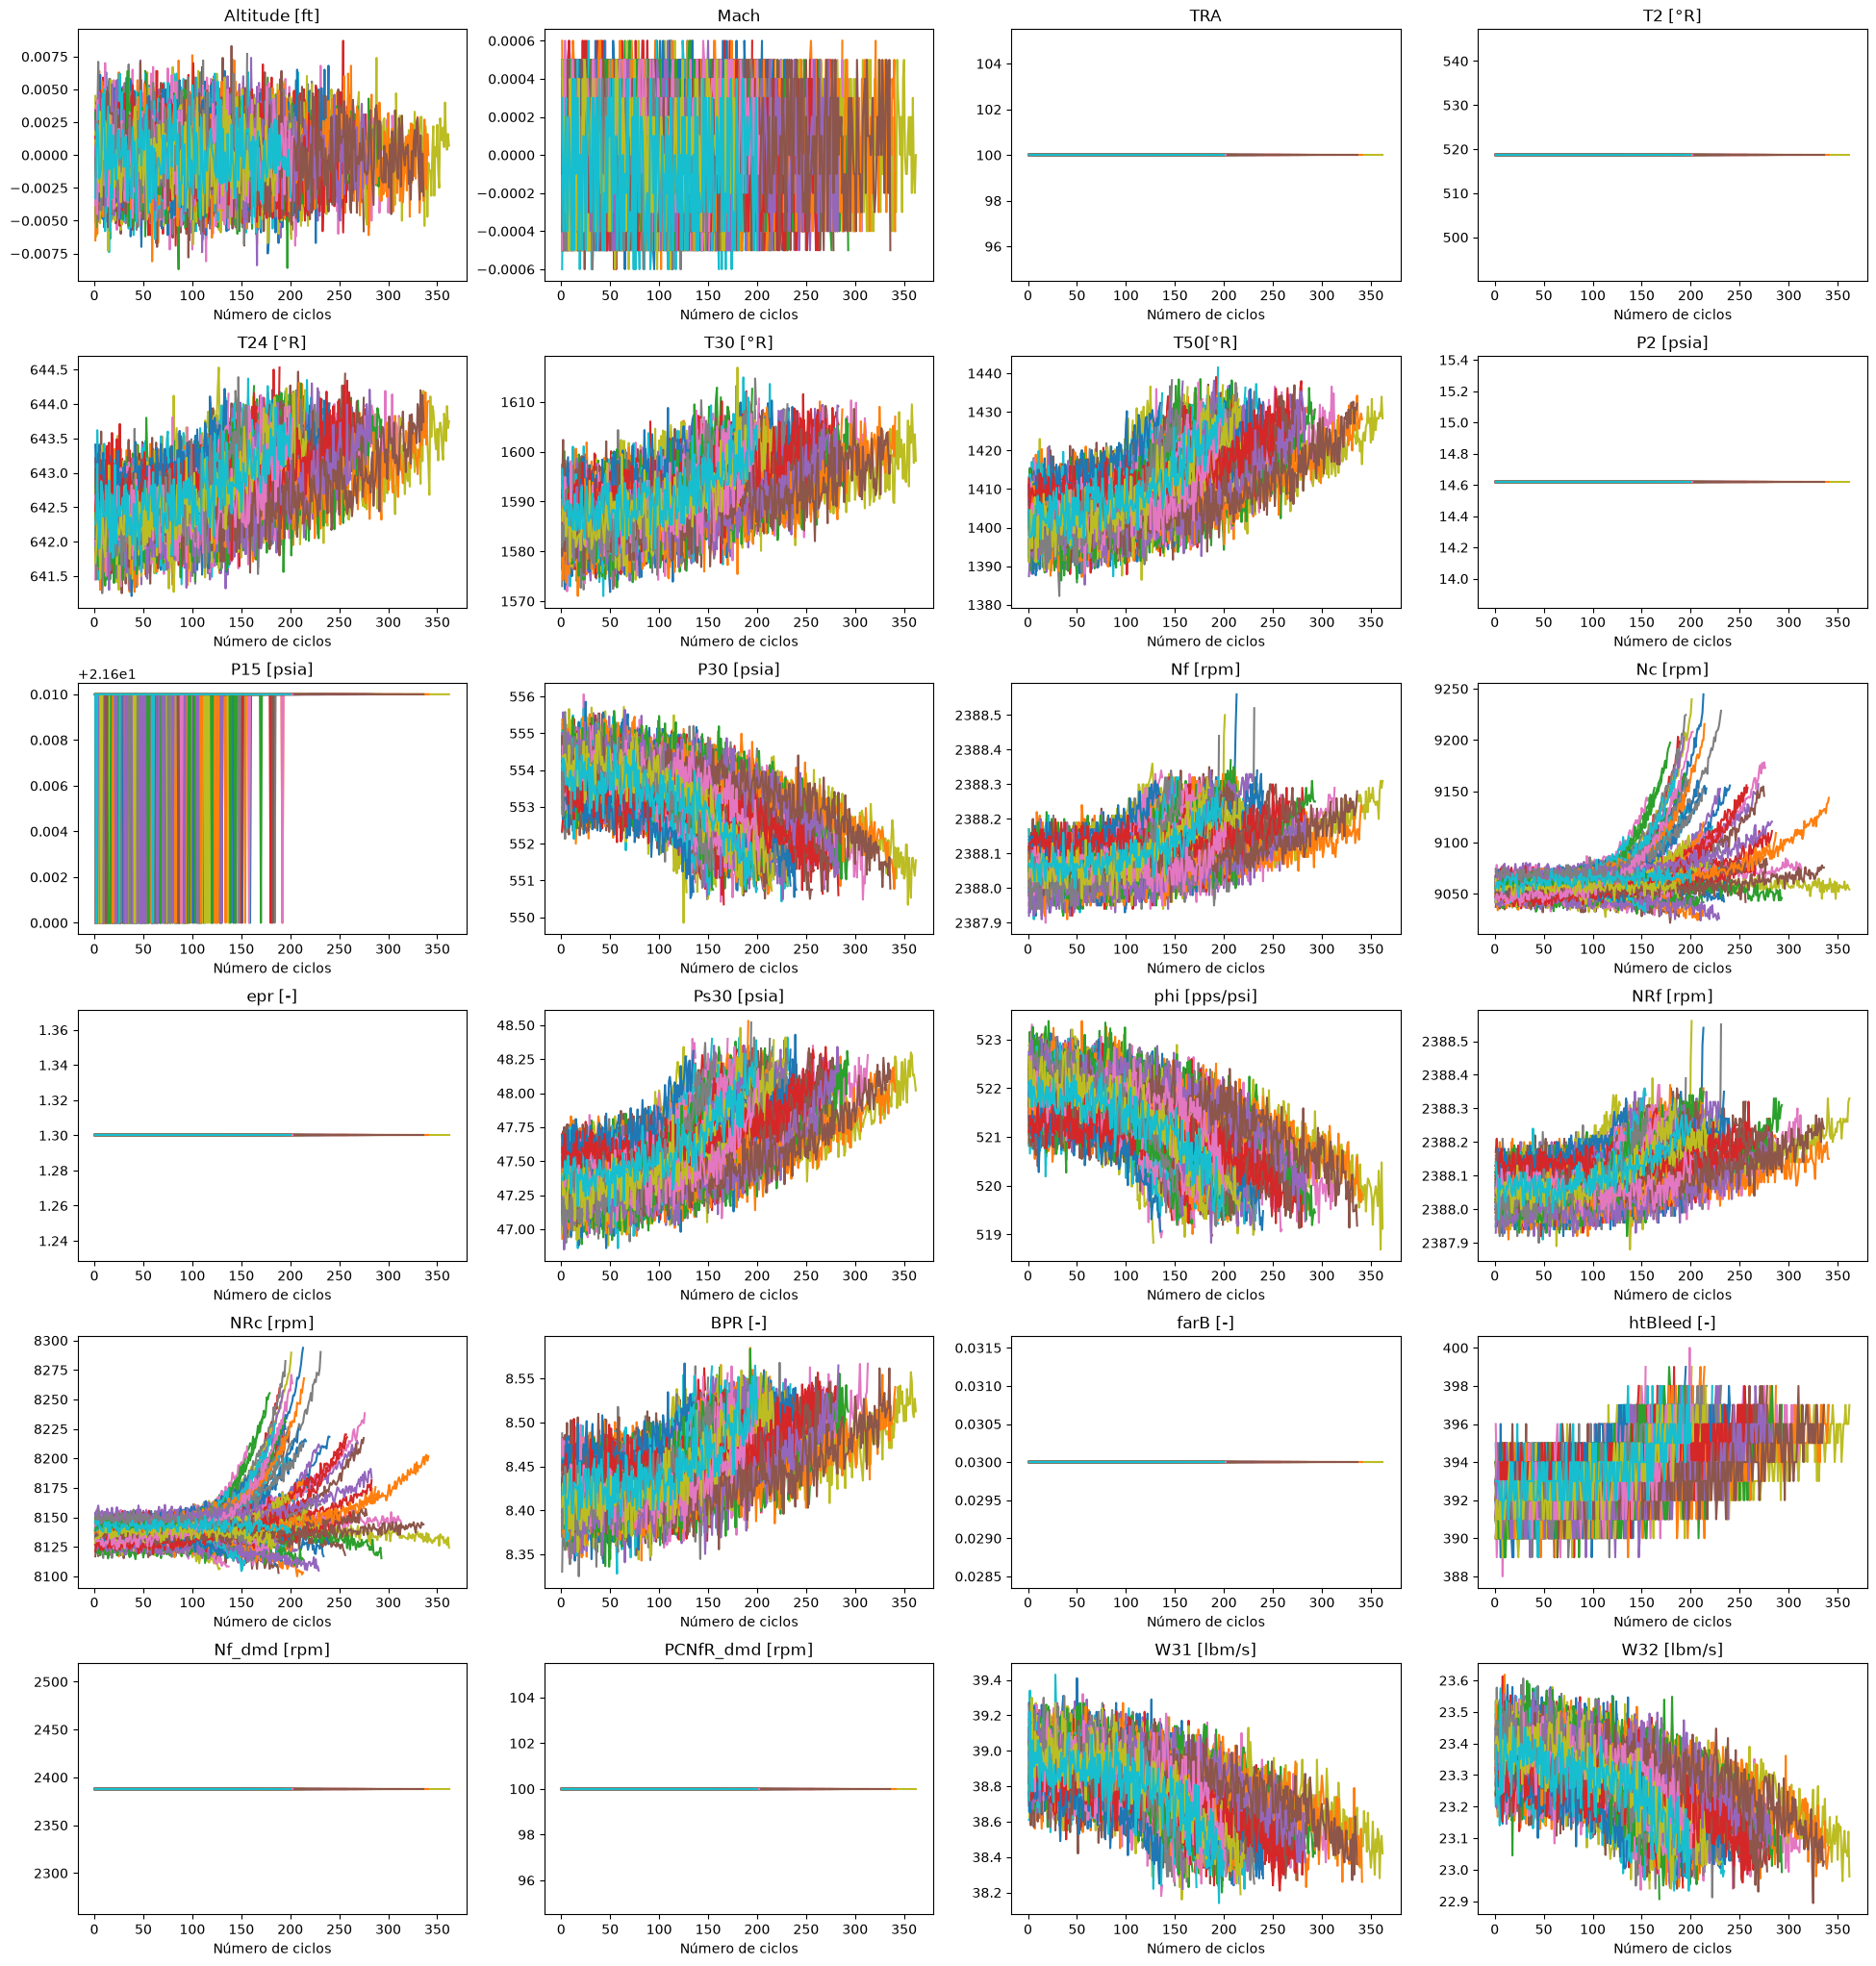

b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x07\x9e\x00\x00\x07\xfc\x08\x06\x00\x00\x00j%6\'\x00\x00\x00:tEXtSoftware\x00Matplotlib version3.11.2, https://matplotlib.org/\x80\x8d\xee\x00\x00\x00\x00\tpHYs\x00\x00\x0fa\x00\x00\x0fa\x01\xa8?\xa7i\x00\x01\x00\x00IDATx\x9c\xec\x9d\x07\xbc\x1cU\xf9\xfe\x9f\x99\xdd\xbd\xfd\xa6\xf7\n\x04\x08-\xb4\xd0\x8b\x94\x00R\x04\x14\x10P\x01\x05\x01\xd1\x1f\xa0\xa0?\xfdS,\x88\xfcP\x04\x14\x05Ai\x82T\x01! \x1dR \x05\x12\x92\x00\xe9\xbd\'7\xf7\xde\xdc^\xb6\xcd\xcc\xff\xf3\x9e\x99\xd9=g\xca\xee\xde\x92\xe4&y\xbf|\xc2\xdd\x9d\x9drfvvg\xf6<\xe7y^\xcd\xb2,\x0b\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xd3I\xf4\xce.\xc80\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30,<3\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30]\x86\x1d\xcf\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30\x0c\xc30L\x97`\xe1\x99a\x18\x86a\x18\x86a\x18\x86a\x18\x86a\x18\x86a\x18\x86a\x18\x86\xe9\x12,<3\x0c\xc30\x0c\xc30\x0c\xc30

In [3]:
fig, axes = plt.subplots(nrows=6, ncols=4, figsize=(24, 20))
axes = axes.ravel()
for i, item in enumerate(train_df.columns[2:]):
    train_df.groupby(ID_COLUMN).plot(
        kind="line", x=CYCLE_COLUMN, y=item, ax=axes[i]
    )
    axes[i].set_title(f"{item}")
    axes[i].get_legend().remove()
    axes[i].set_xlabel("Número de ciclos")
    axes[i].set_ylabel("")

plt.subplots_adjust(top=0.99, bottom=0.01, hspace=0.3, wspace=0.2)
show_figure(fig, FIGURES_DIR / "sensors.png")

## Features, targets e janelas temporais

In [4]:
train_model, test_model = drop_unused_sensor_columns(train_df, test_df)
rul_train = compute_train_rul(train_model, limit=RUL_LIMIT)
rul_test = compute_test_rul(test_model, rul_df, limit=RUL_LIMIT)

windowed = create_fd001_windowed_features(
    train_model,
    test_model,
    rul_train,
    rul_test,
    window_size=WINDOW_SIZE,
    step=WINDOW_STEP,
)
x_train, y_train = windowed.x_train, windowed.y_train
x_test, y_test = windowed.x_test, windowed.y_test

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(17731, 30, 17) (17731,)
(10196, 30, 17) (10196,)


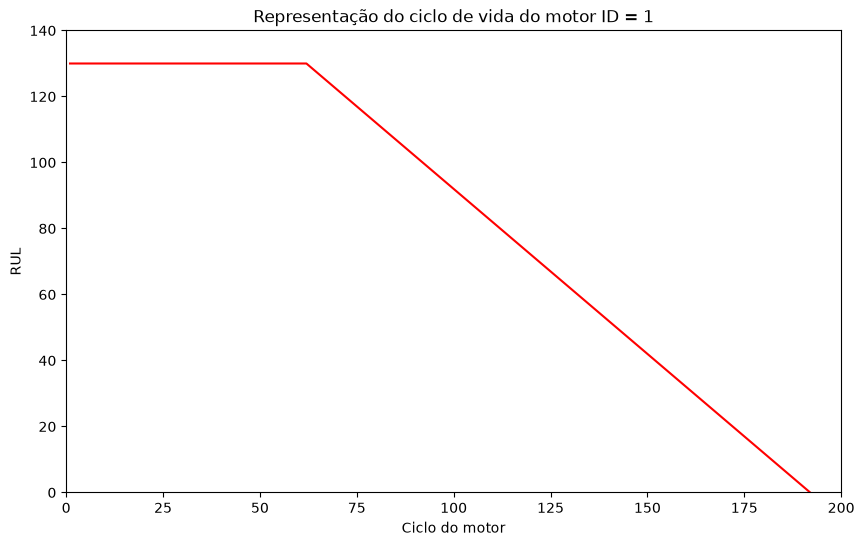

b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x03`\x00\x00\x02"\x08\x06\x00\x00\x00\xaeu\xabw\x00\x00\x00:tEXtSoftware\x00Matplotlib version3.11.2, https://matplotlib.org/\x80\x8d\xee\x00\x00\x00\x00\tpHYs\x00\x00\x0fa\x00\x00\x0fa\x01\xa8?\xa7i\x00\x00b\xdeIDATx\x9c\xed\xdd\x07x\x94U\xda\xc6\xf1;\x81\xd0\xeb\xd2U\x8a\xa0`Yem\xf4\xde\xa5\x88\xa0\x14)\xa2\x80\x88\x88\x1d\x16qEdE\xb1\x83\xd8@\x14uAP)J\x13Az\x07E`Ep\xa5\x83\x80\xa0\x06\x88\xf4\x92\xf9\xae\xe7}M\xbe$\x04\x98\x90I\xde)\xff\xdfu\x0523of\xce\x9c\x99d\xe6\x9es\xces\xa2|>\x9fO\x00\x00\x00\x00\x80\x0c\x17\x9d\xf17\x01\x00\x00\x00\x00 \x80\x01\x00\x00\x00@&b\x04\x0c\x00\x00\x00\x002\t\x01\x0c\x00\x00\x00\x002\t\x01\x0c\x00\x00\x00\x002\t\x01\x0c\x00\x00\x00\x002\t\x01\x0c\x00\x00\x00\x002\t\x01\x0c\x00\x00\x00\x002\t\x01\x0c\x00\x82\xd4\xf6\xed\xdbU\xbf~}\xddq\xc7\x1d\xda\xbbw\xaff\xcf\x9e\xad\xee\xdd\xbbg\xf8\xedn\xda\xb4IW]u\x95\xa6M\x9b\xa6\xcc\xb2d\xc9\x12\xe76\xbf\xff\xfe\xfbL\xf9\xb9P\xe8\x93\xb4\xde\xbf\xccj\xa3W}\x01\x00\

In [5]:
exemplo = train_df[train_df[ID_COLUMN] == 1]
n_cycles = len(exemplo[CYCLE_COLUMN])
rul_motor1 = compute_train_rul(exemplo, limit=RUL_LIMIT)

plt.figure(figsize=(10, 6))
plt.plot(exemplo[CYCLE_COLUMN].iloc[:n_cycles], rul_motor1[:n_cycles], c="red")
plt.title("Representação do ciclo de vida do motor ID = 1")
plt.ylim(0, 140)
plt.xlim(0, 200)
plt.xlabel("Ciclo do motor")
plt.ylabel("RUL")
show_figure(plt.gcf(), FIGURES_DIR / "rul_engine_1.png")

## Partição treino/validação interna

In [6]:
x1, x2, y1, y2 = split_windowed_data(x_train, y_train, test_size=0.2, random_state=1)

## LSTM: busca de hiperparâmetros e avaliação repetida

In [7]:
best_model, best_params = search_hyperparameters(
    "lstm",
    x1,
    y1,
    x2,
    y2,
    tuner_directory=TUNER_DIR,
    project_name="hyper_lstm_hyperband",
    max_epochs=15,
    factor=3,
    hyperband_iterations=1,
    batch_size=200,
    patience=3,
    overwrite=False,
)

save_best_params(best_params, PARAMS_PATH)
for key, value in best_params.items():
    print(f"{key:15s} -> {value}")

Reloading Tuner from C:\Users\davim\OneDrive\Documents\USP\capacitacao_hbr\tcc\data\processed\keras_tuner\hyper_lstm_hyperband\tuner0.json


C:\Users\davim\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


lstm_0          -> 128
dropout_0       -> 0.4000000000000001
lstm_1          -> 64
dropout_1       -> 0.4000000000000001
dense_0         -> 32
dense_1         -> 1
learning_rate   -> 0.01


C:\Users\davim\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop', because it has 2 variables whereas the saved optimizer has 12 variables. 
  saveable.load_own_variables(store)


 Iteração        MSE      RMSE       MAE       R2      tempo
        1 433.826787 20.828509 17.460832 0.561940 236.403484
        2 274.328741 16.562872 13.557007 0.722994 175.769698
        3 458.526507 21.413232 18.130964 0.536999 248.062201
        4 238.602872 15.446775 11.429365 0.759069 174.959326
        5 272.672941 16.512811 11.771692 0.724666 209.141151
        6 302.625150 17.396125 12.561514 0.694422 228.716539
        7 288.503673 16.985396 11.638774 0.708681 233.261619
        8 287.750484 16.963210 12.348936 0.709441 208.260900
        9 407.933268 20.197358 15.769047 0.588086 204.360313
       10 304.104087 17.438580 12.863204 0.692928 240.770078


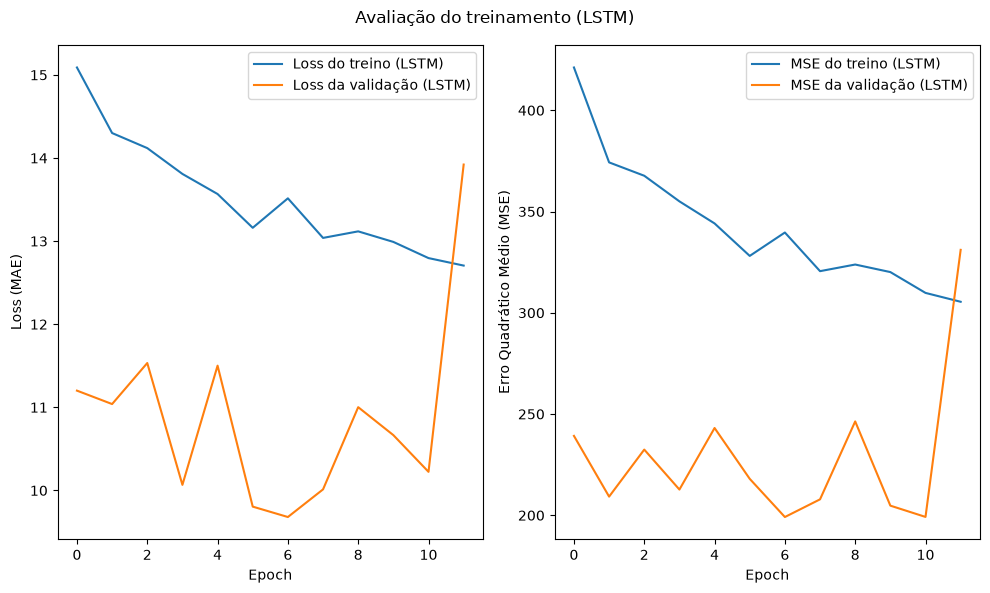

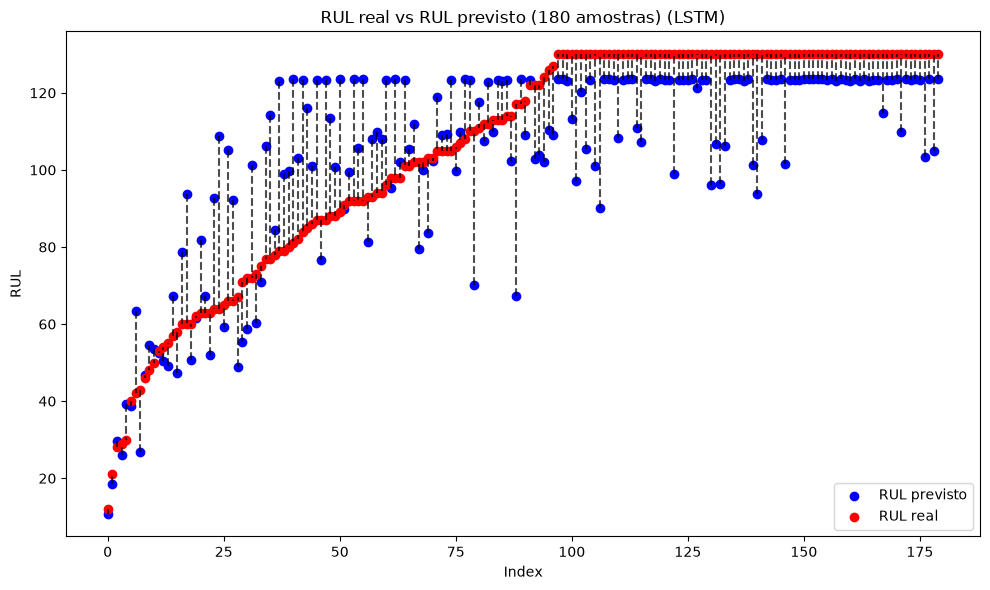

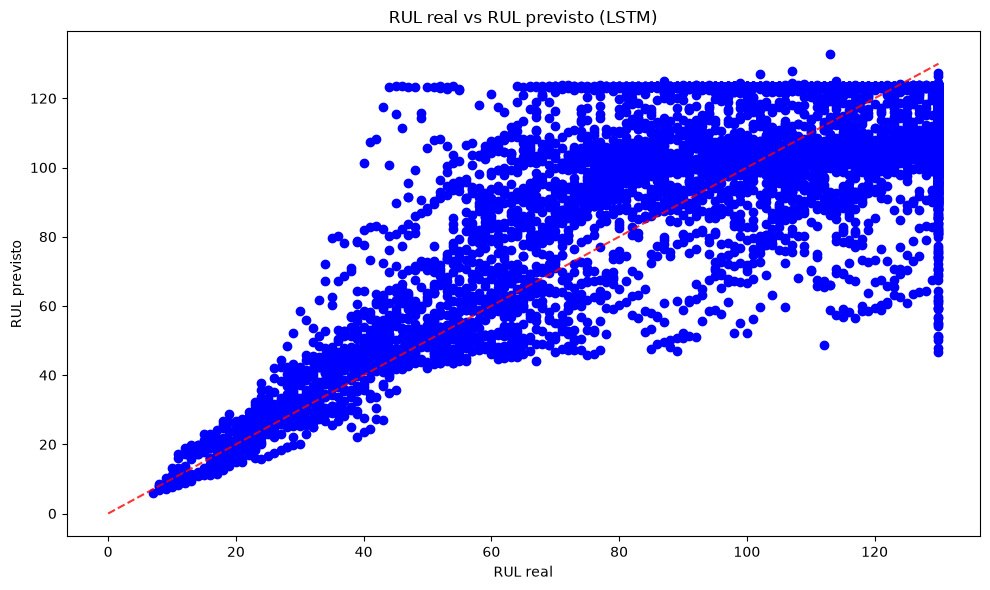

In [8]:
resultados, history = run_repeated_train_eval(
    best_model,
    x1,
    y1,
    x2,
    y2,
    x_test,
    y_test,
    CHECKPOINT,
    n_iterations=N_ITER,
    capture_first_history=True,
)
save_experiment_results(resultados, RESULTS_PATH)
print(resultados.to_string(index=False))

if history is not None:
    plot_training_history(
        history,
        "LSTM",
        save_path=FIGURES_DIR / "lstm_training_history.png",
    )
    y_pred = predict_rul(best_model, x_test)
    plot_rul_prediction_diagnostics(
        y_test,
        y_pred,
        model_label="LSTM",
        rul_limit=RUL_LIMIT,
        figure_dir=FIGURES_DIR,
    )